In [1]:
import pandas as pd
df = pd.read_csv("../../data/merged/score_100/tmdb_numbers_100.csv")

In [2]:
df.head(5)

,tmdb_id,title,original_title,release_date,year,popularity,vote_average,vote_count,adult,rank,domestic_box_office,international_box_office,worldwide_box_office,domestic_share,title_normalized_numbers
0,399579,Alita: Battle Angel,Alita: Battle Angel,2019-01-31,2019,19.5410,7.278,10405,False,20,85838210.0,316061830.0,401900040.0,21.4,alita battle angel
1,530915,1917,1917,2019-12-25,2019,19.0714,7.983,13929,False,22,159227644.0,224482428.0,383710072.0,41.5,NaN
2,757587,1921,1921,2021-07-01,2021,2.2643,5.500,17,False,56,0.0,75017096.0,75017096.0,0.0,NaN
3,1643070,Shelter,Cobijo,2026-03-06,2026,1.8203,6.000,1,False,53,12805541.0,36500000.0,49305541.0,26.0,shelter
4,1767527,Obsession,Одержимость,2026-09-14,2026,1.8521,0.000,0,False,10,263451715.0,253280000.0,516731715.0,51.0,obsession


In [3]:
df.shape
df.info()
df.isna().sum()
df.duplicated().sum()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 728 entries, 0 to 727
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   tmdb_id                   728 non-null    int64  
 1   title                     728 non-null    str    
 2   original_title            728 non-null    str    
 3   release_date              728 non-null    str    
 4   year                      728 non-null    int64  
 5   popularity                728 non-null    float64
 6   vote_average              728 non-null    float64
 7   vote_count                728 non-null    int64  
 8   adult                     728 non-null    bool   
 9   rank                      728 non-null    int64  
 10  domestic_box_office       728 non-null    float64
 11  international_box_office  728 non-null    float64
 12  worldwide_box_office      728 non-null    float64
 13  domestic_share            728 non-null    float64
 14  title_normalized_numb

,tmdb_id,year,popularity,vote_average,vote_count,rank,domestic_box_office,international_box_office,worldwide_box_office,domestic_share
count,7.280000e+02,728.000000,728.000000,728.000000,728.000000,728.000000,7.280000e+02,7.280000e+02,7.280000e+02,728.000000
mean,8.809208e+05,2022.571429,19.901911,6.281174,2559.388736,48.655220,7.944364e+07,1.501090e+08,2.295526e+08,35.861813
std,3.719984e+05,2.304915,42.243011,2.118179,3511.911051,28.980439,1.223527e+08,2.192928e+08,3.207074e+08,24.693630
min,3.870000e+04,2019.000000,1.276100,0.000000,0.000000,1.000000,0.000000e+00,0.000000e+00,1.240098e+07,0.000000
25%,5.680960e+05,2021.000000,3.988225,6.300000,81.750000,22.000000,6.492199e+06,3.373444e+07,5.624103e+07,12.050000
50%,8.235310e+05,2023.000000,13.194300,6.893000,1381.000000,48.000000,3.515716e+07,7.501710e+07,1.135708e+08,41.500000
75%,1.173344e+06,2025.000000,21.714350,7.325250,3544.000000,73.000000,9.688570e+07,1.860996e+08,2.615367e+08,52.300000
max,1.769195e+06,2026.000000,633.508500,9.102000,28768.000000,100.000000,9.465821e+08,1.977904e+09,2.721304e+09,100.000000


array([[<Axes: title={'center': 'popularity'}>,
        <Axes: title={'center': 'vote_average'}>],
       [<Axes: title={'center': 'vote_count'}>,
        <Axes: title={'center': 'domestic_box_office'}>],
       [<Axes: title={'center': 'international_box_office'}>,
        <Axes: title={'center': 'worldwide_box_office'}>]], dtype=object)

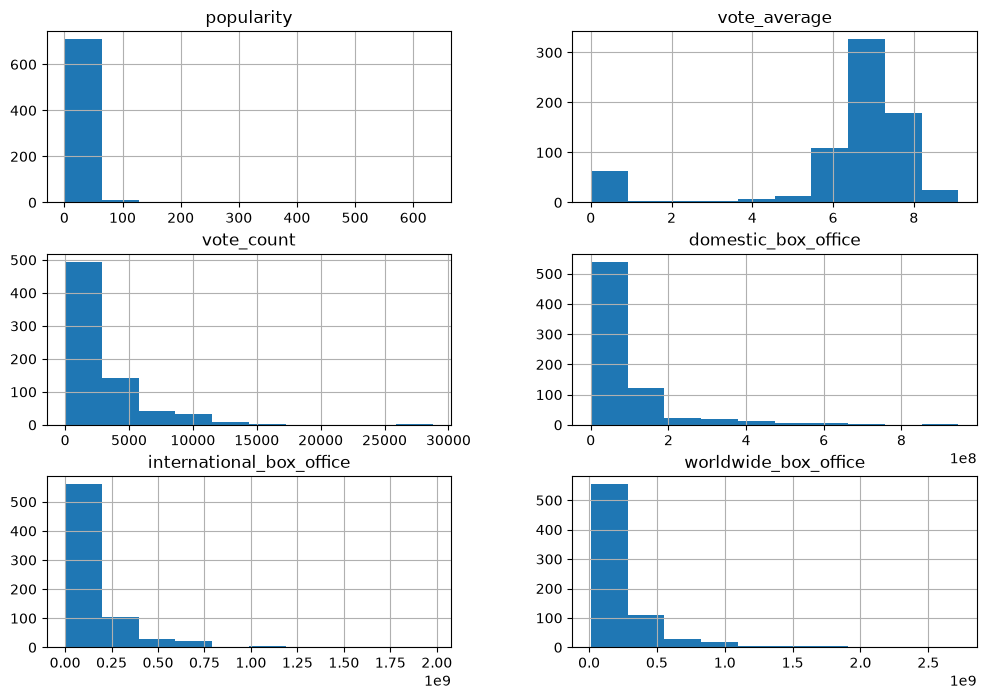

In [4]:
df[['popularity', 'vote_average', 'vote_count',
    'domestic_box_office', 'international_box_office',
    'worldwide_box_office']].hist(figsize=(12,8))

In [5]:
df.nlargest(10, 'popularity')[['title', 'popularity']]

,title,popularity
563,Spider-Man: Brand New Day,633.5085
564,Resident Evil,513.2853
565,The End of Oak Street,413.3113
566,Coyote vs. Acme,347.0415
567,The Odyssey,333.2210
477,Colony,243.0215
478,Mutiny,209.3601
559,Toy Story 5,170.4058
560,Moana,162.0438
561,Obsession,143.1283


<Axes: xlabel='popularity', ylabel='vote_average'>

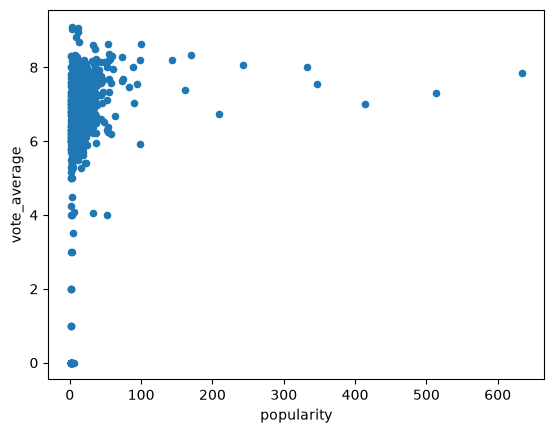

In [6]:
df.plot.scatter(x='popularity', y='vote_average')

<Axes: xlabel='vote_count', ylabel='vote_average'>

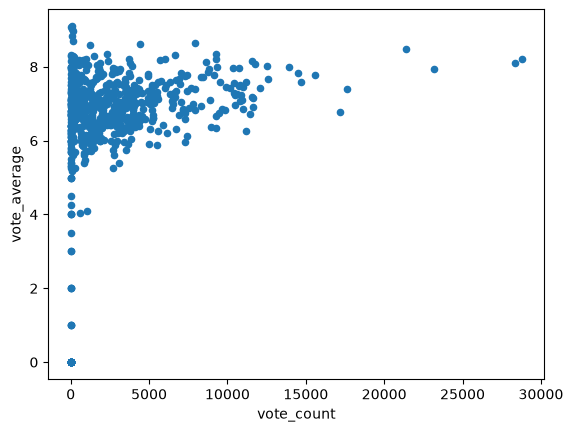

In [7]:
df.plot.scatter(x='vote_count', y='vote_average')

<Axes: xlabel='popularity', ylabel='worldwide_box_office'>

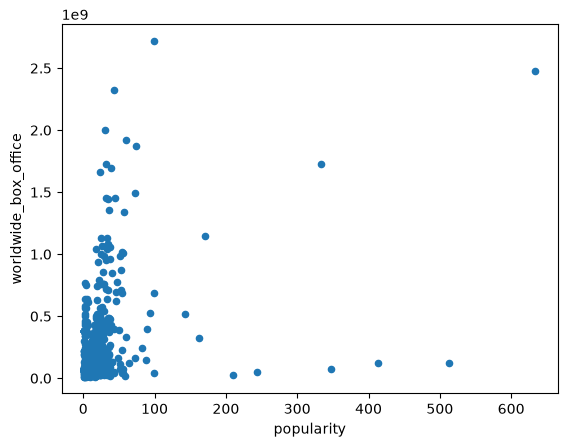

In [8]:
df.plot.scatter(x='popularity', y='worldwide_box_office')

In [9]:
numeric_cols = [
    'popularity',
    'vote_average',
    'vote_count',
    'rank',
    'domestic_box_office',
    'international_box_office',
    'worldwide_box_office'
]

df[numeric_cols].corr()

,popularity,vote_average,vote_count,rank,domestic_box_office,international_box_office,worldwide_box_office
popularity,1.000000,0.191307,0.155610,-0.211156,0.368825,0.285001,0.335588
vote_average,0.191307,1.000000,0.307938,-0.179780,0.105564,0.128060,0.127838
vote_count,0.155610,0.307938,1.000000,-0.424287,0.571090,0.436924,0.516635
rank,-0.211156,-0.179780,-0.424287,1.000000,-0.580304,-0.638188,-0.657770
domestic_box_office,0.368825,0.105564,0.571090,-0.580304,1.000000,0.741561,0.888572
international_box_office,0.285001,0.128060,0.436924,-0.638188,0.741561,1.000000,0.966690
worldwide_box_office,0.335588,0.127838,0.516635,-0.657770,0.888572,0.966690,1.000000


| Analyse                               | Question                                                     |
| ------------------------------------- | ------------------------------------------------------------ |
| `popularity` ↔ `vote_average`         | Popularité et qualité perçue sont-elles liées ?              |
| `popularity` ↔ `worldwide_box_office` | Popularité et succès commercial sont-ils liés ?              |
| `vote_count` ↔ `vote_average`         | Le nombre de votes influence-t-il les notes observées ?      |
| `year` ↔ `worldwide_box_office`       | Comment évolue le succès commercial dans le temps ?          |
| `domestic_share`                      | Quelle proportion du box-office vient du marché domestique ? |
